<a href="https://colab.research.google.com/github/julihdez36/Statistics/blob/main/Estadistica3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cap 3. Probabilidad


La teoría de la probabilidad constituye la base de la estadística ya que las inferencias que hagamos sobre la población se moverá dentro de unos margenes de error, controlado en términos de probabilidades.

Habitualmente estudiamos un fenómeno aleatorio asumiendo un modelo probabilístico y admitiremos como validas las propiedades que nos sugieren en la interpretación del fenómeno.

Pueden distinguirse dos niveles del análsis:
1. **Nivel 1:** elementos básicos como el Espacio muestral $\Omega$  y la probabilidad $P$ con la que estos serán seleccionados para dar lugar a la muestra.

La probabilidad $P$ estará definida sobre el conjunto de partes del espacio muestral $\Omega$ o el conjunto de todos sus subconjuntos posibles, no sobre el espacio muestral, ya que podemos considerar la probabilidad de extraer a Juan y José, como la de extraer a todos los varones de una muestra. Este conjunto de las partes del espacio muestral lo denominamos **Espacio de sucesos**, $\mathcal{A}$, teniendo así los tres componente basicos del cálculo de probabilidades que recibe el nombre de **Espacio de probabilidades**:

$$
(\Omega, \mathcal{A}, \mathcal{P})
$$

En situaciones mas generales, el espacio muestral podrá ser más complejo y el Espacio de sucesos $\mathcal{A}$ requerirá una estructura mas sofisticadas que recibiran el nombre de $\sigma - algebra$.

Como hemos señalado, nos interes observar características $X$ en los individuos del espacio muestral. Esta caracteristica es una variable estadística que al estár sometida a la aleatoriedad del muestreo, no permite conocer su valor con seguridad sino con una cierta probabilidad, dando lugar a lo que denominaremos una variable aleatorio, determinada por un modelo probabilístico.

Pasamos a así de un nivel I, básico, formado por un espacio muestral, un $\sigma -algebra$ y una función de probabilidad, a un nivel II, donde $X$ es una transformación de Omega en el conjunto de los reales

$$
X: \Omega \rightarrow \mathbb{R}
$$

## Espacio muestral

El conjunto de todos los resultados posibles diferentes de un determinado experimento aleatorio se denomina **Espacio muestral** asociado a experimento aleatorio y se suele represenar por $\Omega$. Los elementos de $\Omega$ se les denomina **sucesos elementales**.

Puede haber espacios muestrales finitos (numerables) o continuos, y en términos abstractos, no es mas que un conjunto abstracto de puntos. De ahí que resulte util la teoría de conjuntos.

Si tenemos un $\sigma - algebra$ $\mathcal{A}$ que representa el conjuto de partes de $\Omega$, cada subconjunto de $\Omega$, que llamaremos **sucesos** tendrán asociados una incertidumbre, que cuantificaremos entre 0 y 1 como medida de incertidumbre, que es lo que llamamos probabilidad, P.

$$
P: \mathcal{A} \rightarrow [0,1]
$$

Nótese que $\mathcal{A}$ es un conjunto y por tanto debe ser tratado como tal, donde el Conjunto vacío representa un suceso imposible y el espacion total $\Omega$ será un seceso seguro.

Imagine el experimento aleatorio de lanzar un dado y registrar su cara superior:

In [3]:
omega <- c(1,2,3,4,5,6)
omega

A <- unlist(
  lapply(0:6, function(k) {
    combn(omega, k, simplify = FALSE)
  }),
  recursive = FALSE
)

A_texto <- sapply(A, function(x) {
  paste0("{", paste(x, collapse = ", "), "}")
})

A_texto


[1] 1 2 3 4 5 6

[1] "{}"                 "{1}"                "{2}"               
 [4] "{3}"                "{4}"                "{5}"               
 [7] "{6}"                "{1, 2}"             "{1, 3}"            
[10] "{1, 4}"             "{1, 5}"             "{1, 6}"            
[13] "{2, 3}"             "{2, 4}"             "{2, 5}"            
[16] "{2, 6}"             "{3, 4}"             "{3, 5}"            
[19] "{3, 6}"             "{4, 5}"             "{4, 6}"            
[22] "{5, 6}"             "{1, 2, 3}"          "{1, 2, 4}"         
[25] "{1, 2, 5}"          "{1, 2, 6}"          "{1, 3, 4}"         
[28] "{1, 3, 5}"          "{1, 3, 6}"          "{1, 4, 5}"         
[31] "{1, 4, 6}"          "{1, 5, 6}"          "{2, 3, 4}"         
[34] "{2, 3, 5}"          "{2, 3, 6}"          "{2, 4, 5}"         
[37] "{2, 4, 6}"          "{2, 5, 6}"          "{3, 4, 5}"         
[40] "{3, 4, 6}"          "{3, 5, 6}"          "{4, 5, 6}"         
[43] "{1, 2, 3, 4}"       "{1, 2, 3, 5}"       "{1, 2, 3, 6}"      
[46] "{1, 2, 4, 5}"       "{1, 2, 4, 6}"       "{1, 2, 5, 6}"      
[49] "{1, 3, 4, 5}"       "{1, 3, 4, 6}"       "{1, 3, 5, 6}"      
[52] "{1, 4, 5, 6}"       "{2, 3, 4, 5}"       "{2, 3, 4, 6}"      
[55] "{2, 3, 5, 6}"       "{2, 4, 5, 6}"       "{3, 4, 5, 6}"      
[58] "{1, 2, 3, 4, 5}"    "{1, 2, 3, 4, 6}"    "{1, 2, 3, 5, 6}"   
[61] "{1, 2, 4, 5, 6}"    "{1, 3, 4, 5, 6}"    "{2, 3, 4, 5, 6}"   
[64] "{1, 2, 3, 4, 5, 6}"

## Concepto de probabilidad

¿Cómo asignar probabilidades acada uno de los sucesos de $\mathcal{A}$? En casos sencillos bastará con asignar probabilidades a los sucesos elementales, en otros sera preciso asumir un Modelo probabilístico que podrá ser validado inferencialmente.

**1. concepto frecuentista:** un hecho empíricamente comprobado es que la frecuencia relativa de un suceso tiende a estabilziarse cuando la frecuencia absoluta aumenta, lo que sugiere que la probabilidad de un suceso puede entenderse como un número ideal al que converge su frecuenica reltiva cuando la frecuencia total tiende a infinito ¿qué tan grande debe ser n?¿qué hacer cuándo no se puede aumentar n?

Siguiendo con nuestro ejemplo del dado, ¿Qué probabilidad hay de que salga 6 al tirar un dado?

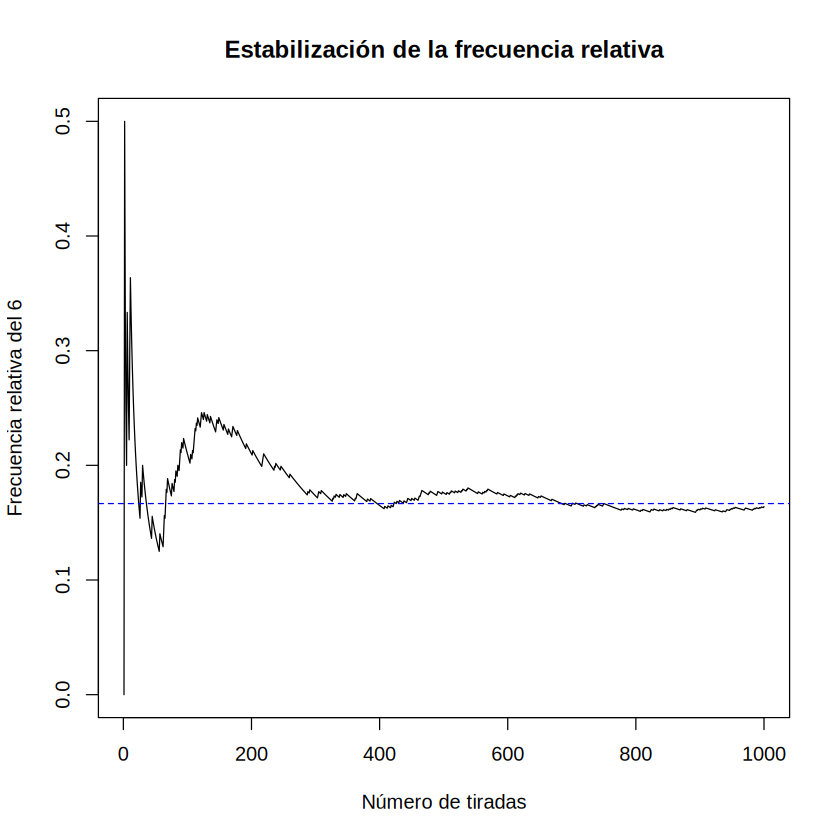

In [4]:
set.seed(123)  # Para reproducir el experimento

n <- 1000

# Simular 1000 tiradas
tiradas <- sample(1:6, size = n, replace = TRUE)

# ¿Cuándo salió un 6?
es_seis <- tiradas == 6

# Frecuencia absoluta acumulada de seises
frecuencia_absoluta <- cumsum(es_seis)

# Número de tiradas
num_tiradas <- 1:n

# Frecuencia relativa acumulada
frecuencia_relativa <- frecuencia_absoluta / num_tiradas

plot(
  num_tiradas,
  frecuencia_relativa,
  type = "l",
  xlab = "Número de tiradas",
  ylab = "Frecuencia relativa del 6",
  main = "Estabilización de la frecuencia relativa"
)

# Probabilidad teórica de obtener un 6
abline(h = 1/6, lty = 2, col = "blue")

**2. Concepto clásico:**

Está basado en el denominado **principio de la razón insuficiente**,el cual postula que si no exite un fundamento para preferir una, entre varias prosibilidades, todas deben ser consideradas equiprobables.

**Laplace** recogió esta idea y formuló la regla clásica del cociente entre casos favorables y casos posibles.

## Definición formal de probabilidad

kolmogorov desarrolla una definición axiomatica de probablidad. Llamaremos probabilidad a una aplicación

$$
P: \mathcal{A} \rightarrow [0,1]
$$

Tal que:

- **axioma 1:** Para todo suceso A de $\mathcal{A}$
$$
P(A) \geq 0 \ \forall A \in \mathcal{A}
$$

- **axioma 2:**
$$
P(\Omega) = 1
$$

- **axioma 3:** Para toda colección de sucesos incompatibles o disjuntos, $\{A_{i}\}$ con $A_{i} \cap A_{j} = \emptyset, i \neq j$ se tiene que:

$$
P(\bigcup_{i=1}^{\infty} A_{i}) = \sum_{i=1}^{\infty} P(A_{i})
$$

Esta definición no dice cómo asignar las probabilidades, sólo dice que cualquier asignación que hagamos debe verificar estos tres axiomas para que pueda llamarse Probabilidad.


## Asignación de probabilidad en espacios muestrales discretos

Para asignar una probabilidad es suficiente con conocer la probabilidad de sucesos elementales, ya que Los demás sucesos pueden calcularse con base en los elementales. La asignación debe satisfacer los axiomas a la vez que es empíricamente consistente.

No obstante, generalmente lo que se hace es atribuir un **modelo de probabilidad** global al fenómeno estudiado, lo que se conoce como una **Distribución de probabilidad**. Siendo uno de los más famosos el modelo uniforme.

## Modelo uniforme

En este modelo se asume que los sucesos elementales de $\Omega$ se consideran como equiprobables, el cual, recordemos, son sucesos incompatibles o sijuntos, por lo que su calcuo es sencillo, ya que:

$$
1 = P(\Omega) = nP(w_{i})
$$

El cálculo de probabilidades de un sucesos en un modelo uniforme es equivalente al cociente de laplace, casos favorables sobre numero de casos posibles, con $k$ casos favorables

$$
P(A) = \frac{k}{n}
$$

El computo deberá considerar las fórmulas de las variaciones, combinaciones y permutaciones.














In [3]:
Omega <- c("A", "B", "C") # espacio muestral

combn(Omega, 2)

#install.packages("gtools") # Solo una vez
library(gtools)

permutations(n = 3, r = 2, v = Omega)



A,A,B
B,C,C


A,B
A,C
B,A
B,C
C,A
C,B



#### Probabilidad condicionada

Dado que mediante un espacio probabilístico establecemos una formulación matemática a un fenómeno aleatorio que estamos observando, parece razonable pensar que si sucede algo que aporta información a nuestro fenómeno aleatorio, esto debe alterar el espacio aleatorio de partida.

Considerese la extracción de una bola blanca de una urna con tres bolas blancas y dos negras bajo una función uniforme 1/5.
